# 第4章　ガウス過程による予測
同じ材料を異なる温度で処理したときの合成強度を予測します。温度 $T$ は $x=(T-140\,^\circ\mathrm{C})/(40\,^\circ\mathrm{C})$ で $[0,1]$ に写します。まず学習済みGPで予測を描き、次に学習を止めた二点の例で計算を追います。各図のPDFとSVGは実行時に再生成されます。

**ゴール** 6件からGPを学習し、潜在強度と新しい1回の測定値の区間を、同じ温度で読み分けます。続く二点例では平均と共分散を数式と照合します。

In [1]:
import json
from math import sqrt

import gpytorch
import matplotlib.pyplot as plt
import torch
from gpytorch.kernels import MaternKernel, RBFKernel, ScaleKernel
from gpytorch.means import ZeroMean
from robotorchan.models import SingleTaskGP

from experiment import (
    BLUE, DTYPE, GREEN, NOISE_SD, ORANGE, QUALITY,
    fit_material_gp, material_strength, observations, save_figure, setup,
)

setup()
train_x, train_y, train_yvar = observations()
model = fit_material_gp(train_x, train_y, train_yvar)
grid = torch.linspace(0, 1, 301, dtype=DTYPE).unsqueeze(-1)
print("入力、強度、観測分散:", train_x.shape, train_y.shape, train_yvar.shape)
print("観測強度 [MPa]:", train_y.squeeze(-1).tolist())

入力、強度、観測分散: torch.Size([6, 1]) torch.Size([6, 1]) torch.Size([6, 1])
観測強度 [MPa]: [77.92536345054386, 83.06292043343063, 80.2427772717856, 65.7292665267901, 62.27232319841271, 74.10807719569486]


## 4.1 潜在関数と次の測定値
本の図1と同じ図を再現します。次の1回にも標準偏差2 MPaの独立なノイズを加えます。`latent.variance` は温度ごとの潜在強度の分散、`measurement.variance` は将来の測定値の分散です。どちらも単位は MPa² です。図の黒い縦線で平均と区間を読み取り、直後のセルの数値で確かめてください。

新規観測と潜在関数の分散差: 4.0000 MPa²


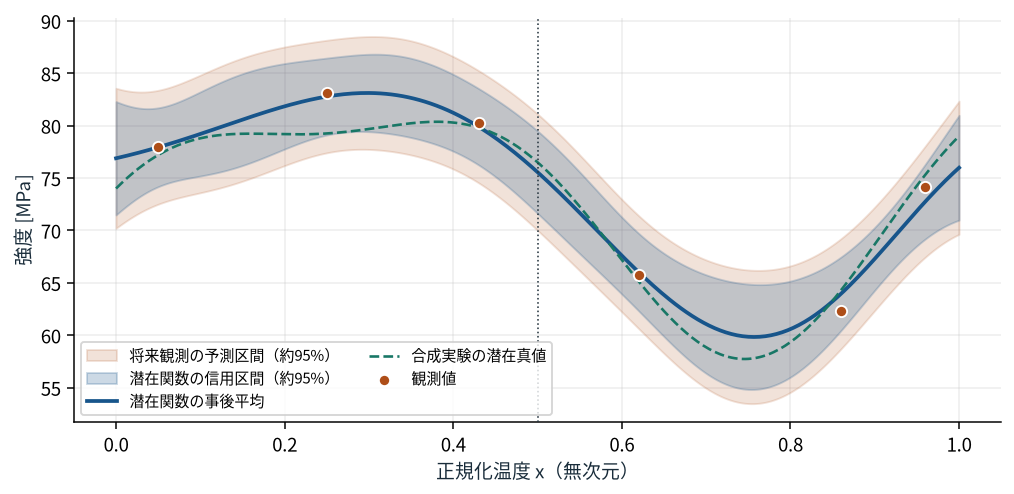

In [2]:
with torch.no_grad():
    latent = model.posterior(grid)
    measurement = model.posterior(grid, observation_noise=True)
    mean = latent.mean.squeeze(-1)
    latent_sd = latent.variance.sqrt().squeeze(-1)
    measurement_sd = measurement.variance.sqrt().squeeze(-1)
    difference = measurement.variance - latent.variance
torch.testing.assert_close(difference, torch.full_like(difference, NOISE_SD**2))

x_axis = grid.squeeze(-1)
fig, ax = plt.subplots(figsize=(7.4, 3.55), layout="constrained")
ax.fill_between(x_axis, mean - 1.96 * measurement_sd, mean + 1.96 * measurement_sd,
                color=ORANGE, alpha=0.16, label="将来観測の予測区間（約95%）")
ax.fill_between(x_axis, mean - 1.96 * latent_sd, mean + 1.96 * latent_sd,
                color=BLUE, alpha=0.22, label="潜在関数の信用区間（約95%）")
ax.plot(x_axis, mean, color=BLUE, linewidth=2, label="潜在関数の事後平均")
ax.plot(x_axis, material_strength(grid).squeeze(-1), "--", color=GREEN,
        linewidth=1.4, label="合成実験の潜在真値")
ax.scatter(train_x, train_y, color=ORANGE, edgecolor="white", zorder=4, label="観測値")
ax.axvline(0.5, color="#273640", linewidth=0.85, linestyle=":", zorder=3)
ax.set(xlabel="正規化温度 x（無次元）", ylabel="強度 [MPa]")
ax.legend(loc="lower left", fontsize=8, ncols=2)
save_figure(fig, "ch04_prediction_intervals")
print(f"新規観測と潜在関数の分散差: {difference.mean().item():.4f} MPa²")

In [3]:
mid = 150  # 301点の等間隔グリッドで x = 0.50 に対応する位置
assert torch.isclose(grid[mid, 0], grid.new_tensor(0.5))
mu_mid = mean[mid].item()
print(f"x = {grid[mid, 0].item():.2f}, T = {140 + 40 * grid[mid, 0].item():.0f} °C")
print(f"事後平均 = {mu_mid:.2f} MPa")
for label, standard_deviation in (
    ("潜在強度", latent_sd[mid].item()),
    ("新しい1回の測定値", measurement_sd[mid].item()),
):
    lower = mu_mid - 1.96 * standard_deviation
    upper = mu_mid + 1.96 * standard_deviation
    print(f"{label}: 標準偏差 {standard_deviation:.2f} MPa / 区間 [{lower:.2f}, {upper:.2f}] MPa")


x = 0.50, T = 160 °C
事後平均 = 75.56 MPa
潜在強度: 標準偏差 2.00 MPa / 区間 [71.63, 79.49] MPa
新しい1回の測定値: 標準偏差 2.83 MPa / 区間 [70.01, 81.11] MPa


## 4.3 2観測・2予測の手計算との照合
正規化入力を $x=(0,1)$、予測先を $x_*=(0.25,0.75)$ とします。零平均・振幅分散 1 の RBF と長さ尺度 0.5、既知の観測分散 0.1 を固定します。出力の単位はこの節の検算用の無次元量です。$A=K(X,X)+0.1I$ として、逆行列の代わりに Cholesky 分解による連立方程式を解きます。検算用の式を既存APIの出力と比較します。

In [4]:
small_x = torch.tensor([[0.0], [1.0]], dtype=DTYPE)
small_y = torch.tensor([[1.0], [-0.5]], dtype=DTYPE)
check_noise_variance = 0.1
small_var = torch.full_like(small_y, check_noise_variance)
small_test = torch.tensor([[0.25], [0.75]], dtype=DTYPE)

rbf = ScaleKernel(RBFKernel()).to(dtype=DTYPE)
rbf.base_kernel.lengthscale = 0.5
rbf.outputscale = 1.0
fixed = SingleTaskGP(
    small_x, small_y, train_Yvar=small_var, covar_module=rbf,
    mean_module=ZeroMean(), outcome_transform=None,
).eval()

with torch.no_grad():
    # PyTorchの公開APIで RBF の行列を計算し、独立した検算に使う。
    joined = torch.cat((small_x, small_test))
    kernel_matrix = torch.exp(-0.5 * torch.cdist(joined, joined).square() / 0.5**2)
    a = kernel_matrix[:2, :2] + check_noise_variance * torch.eye(2, dtype=DTYPE)
    cross = kernel_matrix[:2, 2:]
    cholesky = torch.linalg.cholesky(a)
    manual_mean = cross.T @ torch.cholesky_solve(small_y, cholesky)
    manual_cov = kernel_matrix[2:, 2:] - cross.T @ torch.cholesky_solve(cross, cholesky)

    # 厳密な小例では高速な分散近似を明示的に無効化する。
    with gpytorch.settings.fast_pred_var(False):
        api = fixed.posterior(small_test)
        api_cov = api.distribution.covariance_matrix

torch.testing.assert_close(manual_mean, api.mean, rtol=1e-8, atol=1e-8)
torch.testing.assert_close(manual_cov, api_cov, rtol=1e-8, atol=1e-8)
print("A =", a)
print("事後平均 =", manual_mean)
print("事後共分散 =", manual_cov)

A = tensor([[1.1000, 0.1353],
        [0.1353, 1.1000]], dtype=torch.float64)
事後平均 = tensor([[ 0.6780],
        [-0.1894]], dtype=torch.float64)
事後共分散 = tensor([[0.2489, 0.1780],
        [0.1780, 0.2489]], dtype=torch.float64)


## 4.6 観測点数・観測ノイズ・カーネルを一つずつ変える
ここでは差の理由を追えるように平均とカーネルの主な値を固定します。行は平均・長さ尺度・信号分散を指定し、データから再推定せずに比較します。ノイズ比較は**同じ観測値**に対しモデルが仮定する測定精度だけを変えます。別の測定ノイズでデータそのものを再生成する実験は、章末の発展課題です。

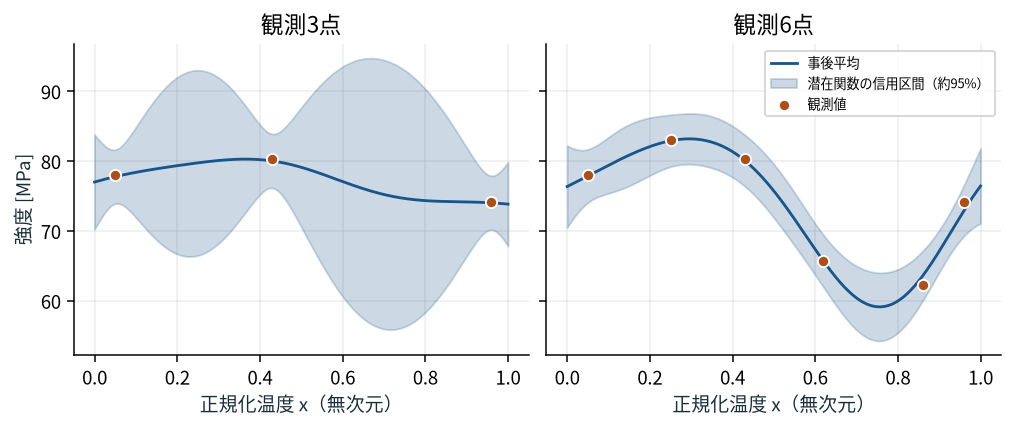

In [5]:
matern_lengthscale = 0.20


def fixed_prior_posterior(indices, noise_sd, kernel_name):
    x, y = train_x[indices], train_y[indices]
    base_kernel = RBFKernel() if kernel_name == "RBF" else MaternKernel(nu=1.5)
    kernel = ScaleKernel(base_kernel).to(dtype=DTYPE)
    kernel.base_kernel.lengthscale = 0.20 if kernel_name == "RBF" else matern_lengthscale
    kernel.outputscale = 12.0**2
    gp = SingleTaskGP(
        x, y - 70.0, train_Yvar=torch.full_like(y, noise_sd**2),
        mean_module=ZeroMean(), covar_module=kernel, outcome_transform=None,
    ).eval()
    with torch.no_grad():
        posterior = gp.posterior(grid)
    return posterior.mean.squeeze(-1) + 70.0, posterior.variance.sqrt().squeeze(-1)


def plot_fixed(ax, indices, noise_sd, kernel_name, title):
    mean_fixed, sd_fixed = fixed_prior_posterior(indices, noise_sd, kernel_name)
    ax.plot(x_axis, mean_fixed, color=BLUE, label="事後平均")
    ax.fill_between(x_axis, mean_fixed - 1.96 * sd_fixed, mean_fixed + 1.96 * sd_fixed,
                    color=BLUE, alpha=0.22, label="潜在関数の信用区間（約95%）")
    ax.scatter(train_x[indices], train_y[indices], color=ORANGE, edgecolor="white",
               zorder=3, label="観測値")
    ax.set_title(title)
    return sd_fixed


small_indices = [0, 2, 5]
all_indices = list(range(len(train_x)))
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.05), sharey=True, layout="constrained")
sd_three = plot_fixed(axes[0], small_indices, 2.0, "RBF", "観測3点")
sd_six = plot_fixed(axes[1], all_indices, 2.0, "RBF", "観測6点")
for ax in axes:
    ax.set_xlabel("正規化温度 x（無次元）")
axes[0].set_ylabel("強度 [MPa]")
axes[1].legend(loc="upper right", fontsize=7)
save_figure(fig, "ch04_observation_count")
assert torch.all(sd_six <= sd_three + 1e-8)

{
  "observations_mpa": [
    77.92536345054386,
    83.06292043343063,
    80.2427772717856,
    65.7292665267901,
    62.27232319841271,
    74.10807719569486
  ],
  "prediction_grid_midpoint_mean_mpa": 75.55802787974477,
  "prediction_grid_midpoint_latent_sd_mpa": 2.003676385727152,
  "prediction_grid_midpoint_measurement_sd_mpa": 2.8310279155671747,
  "fixed_input_order": [
    0.0,
    1.0,
    0.25,
    0.75
  ],
  "fixed_prior_covariance": [
    [
      1.0,
      0.1353352832366127,
      0.8824969025845953,
      0.32465246735834974
    ],
    [
      0.1353352832366127,
      1.0,
      0.32465246735834974,
      0.8824969025845953
    ],
    [
      0.8824969025845953,
      0.32465246735834974,
      1.0,
      0.6065306597126334
    ],
    [
      0.32465246735834974,
      0.8824969025845953,
      0.6065306597126334,
      1.0
    ]
  ],
  "fixed_mean": [
    0.6780044386522548,
    -0.1894126424314832
  ],
  "fixed_covariance": [
    [
      0.24890212379855148,
      0

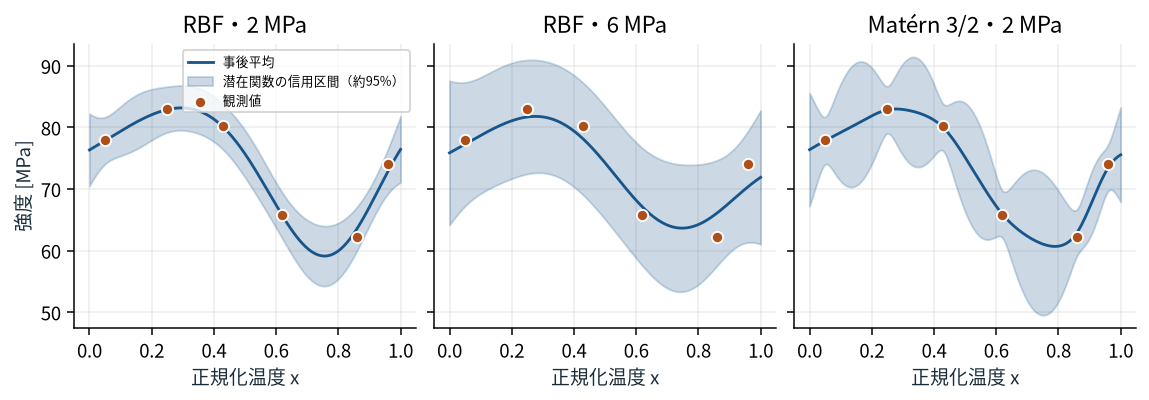

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.85), sharey=True, layout="constrained")
sd_rbf = plot_fixed(axes[0], all_indices, 2.0, "RBF", "RBF・2 MPa")
sd_noisy = plot_fixed(axes[1], all_indices, 6.0, "RBF", "RBF・6 MPa")
sd_matern = plot_fixed(axes[2], all_indices, 2.0, "Matérn", "Matérn 3/2・2 MPa")
for ax in axes:
    ax.set_xlabel("正規化温度 x")
axes[0].set_ylabel("強度 [MPa]")
axes[0].legend(loc="upper right", fontsize=6.7)
save_figure(fig, "ch04_noise_kernel")
assert torch.all(sd_rbf <= sd_noisy + 1e-8)

QUALITY.mkdir(exist_ok=True)
metrics = {
    "observations_mpa": train_y.squeeze(-1).tolist(),
    "prediction_grid_midpoint_mean_mpa": mean[150].item(),
    "prediction_grid_midpoint_latent_sd_mpa": latent_sd[150].item(),
    "prediction_grid_midpoint_measurement_sd_mpa": measurement_sd[150].item(),
    "fixed_input_order": joined[:, 0].tolist(),
    "fixed_prior_covariance": kernel_matrix.tolist(),
    "fixed_mean": manual_mean.squeeze(-1).tolist(),
    "fixed_covariance": manual_cov.tolist(),
    "fixed_mean_max_abs_error": (manual_mean - api.mean).abs().max().item(),
    "fixed_covariance_max_abs_error": (manual_cov - api_cov).abs().max().item(),
    "observation_variance_identity_max_abs_error":
        (difference - NOISE_SD**2).abs().max().item(),
}
(QUALITY / "ch04_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print(json.dumps(metrics, indent=2))

## 章末演習
1. **確認。** 潜在標準偏差が 3 MPa、観測ノイズの標準偏差が 2 MPa のとき、将来の測定値の標準偏差と約95%区間の半幅を求めましょう。
2. **操作。** 二点の検算で `small_var` と検算用 `a` に使う観測分散をともに0.5に変え、事後平均と分散を比較しましょう。
3. **操作。** 同じ6観測でMatérn 3/2の長さ尺度を0.10と0.35に変え、観測間の帯を比べましょう。
4. **発展。** 測定値の生成時に標準偏差を6 MPaに変える場合と、生成済みの同じ測定値に6 MPaを仮定する場合を比較しましょう。

**第5章へ。** `mu_mid` と `latent_sd[mid]` を記録してください。次章の改善の計算は、潜在強度の同じ予測分布から始まります。